<a href="https://colab.research.google.com/github/bhanukaT56/setExercises/blob/tharukshi-exercise04/Exercise4_WidthDepth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 4: Effect of CNN Width and Depth on CIFAR-10 Classification

**PUSL3123 – AI and Machine Learning**  
**Assessment 1**

## Aim

To investigate how different CNN architectures with varying widths and depths affect image classification performance on the CIFAR-10 dataset. The experiments compare validation accuracy, training loss and trainable parameter counts using consistent training settings.

## 1. Data Preparation and Setup

The CIFAR-10 dataset is used to evaluate the CNN architectures. It contains 50,000 training images and 10,000 test images, with 10 different image classes.

The original training dataset is divided into:

- **Training set:** 45,000 images
- **Validation set:** 5,000 images
- **Test set:** 10,000 images

A fixed random seed of 42 is used to ensure a consistent data split. All images are normalised using the CIFAR-10 channel mean and standard deviation.

The same dataset partitions and preprocessing settings are maintained across all experiments to ensure a fair comparison. The test set is reserved for final evaluation.

In [1]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cpu")
print("Device:", device)


MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_train, val_idx),   batch_size=128, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, num_workers=2)


def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()


print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

Device: cpu


100%|██████████| 170M/170M [27:09<00:00, 105kB/s]


Train / val / test sizes: 45000 5000 10000


## 2. CNN Architecture

A configurable Convolutional Neural Network (CNN) is implemented using PyTorch. The architecture consists of convolutional layers, ReLU activation functions, max-pooling layers, a flattening operation and a final fully connected classification layer.

The number of convolutional layers and filters can be adjusted to investigate the effects of CNN width and depth.

### Architecture Components

- **Convolutional Layer:** Extracts image features such as edges, shapes and textures.
- **ReLU Activation:** Introduces non-linearity into the network.
- **Max-Pooling:** Reduces spatial dimensions while retaining important features.
- **Flatten:** Converts feature maps into a one-dimensional vector.
- **Fully Connected Layer:** Produces predictions for the 10 CIFAR-10 classes.

The same model-building function is used for all six experiments, allowing the architectures to be compared under consistent conditions.

In [2]:

def build_cnn(filters):
    layers = []
    in_channels = 3

    for out_channels in filters:
        layers.extend([
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        ])
        in_channels = out_channels

    layers.append(nn.Flatten())

    with torch.no_grad():
        dummy = torch.zeros(1, 3, 32, 32)
        feature_extractor = nn.Sequential(*layers)
        output = feature_extractor(dummy)
        flattened_size = output.shape[1]

    layers.append(nn.Linear(flattened_size, 10))

    return nn.Sequential(*layers)


# Check the CNN architecture
test_model = build_cnn([32, 64])

print(test_model)
print("Trainable parameters:", f"{count_params(test_model):,}")


Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable parameters: 60,362


## 3. Experiment 1 – Effect of CNN Width

The first experiment investigates how the number of filters in a CNN affects classification performance.

Three CNN configurations are tested by increasing the number of filters in the convolutional layers:

- Width 1: [16, 32]
- Width 2: [32, 64]
- Width 3: [64, 128]

All configurations use the same network depth, dataset, preprocessing methods and training settings. Each model is trained for 20 epochs using the Adam optimiser with a learning rate of 0.001.

The final training loss, validation accuracy and number of trainable parameters are recorded to compare the effect of increasing CNN width.

In [3]:

width_configs = {
    "Width 1": [16, 32],
    "Width 2": [32, 64],
    "Width 3": [64, 128]
}

depth_configs = {
    "Depth 1": [32],
    "Depth 2": [32, 64],
    "Depth 3": [32, 64, 128]
}

print("Width Configurations:")
for name, filters in width_configs.items():
    print(name, ":", filters)

print("\nDepth Configurations:")
for name, filters in depth_configs.items():
    print(name, ":", filters)


Width Configurations:
Width 1 : [16, 32]
Width 2 : [32, 64]
Width 3 : [64, 128]

Depth Configurations:
Depth 1 : [32]
Depth 2 : [32, 64]
Depth 3 : [32, 64, 128]


In [4]:

width_results = {}

for name, filters in width_configs.items():

    print(f"\nTraining {name}: Filters {filters}")

    model = build_cnn(filters).to(device)

    params = count_params(model)

    history = fit(
        model,
        train_loader,
        val_loader,
        epochs=20,
        lr=0.001
    )

    width_results[name] = {
        "filters": filters,
        "parameters": params,
        "train_loss": history["train_loss"][-1],
        "val_accuracy": history["val_acc"][-1],
        "history": history
    }

    print("Parameters:", f"{params:,}")
    print("Final Training Loss:", round(history["train_loss"][-1], 4))
    print("Final Validation Accuracy:",
          round(history["val_acc"][-1] * 100, 2), "%")



Training Width 1: Filters [16, 32]
Epoch  1 | train loss 1.506 acc 0.468 | val loss 1.299 acc 0.539
Epoch  2 | train loss 1.194 acc 0.582 | val loss 1.169 acc 0.591
Epoch  3 | train loss 1.064 acc 0.632 | val loss 1.082 acc 0.628
Epoch  4 | train loss 0.989 acc 0.658 | val loss 1.037 acc 0.641
Epoch  5 | train loss 0.937 acc 0.676 | val loss 1.006 acc 0.653
Epoch  6 | train loss 0.892 acc 0.693 | val loss 0.978 acc 0.660
Epoch  7 | train loss 0.859 acc 0.703 | val loss 0.979 acc 0.666
Epoch  8 | train loss 0.826 acc 0.714 | val loss 0.969 acc 0.666
Epoch  9 | train loss 0.795 acc 0.724 | val loss 0.947 acc 0.673
Epoch 10 | train loss 0.778 acc 0.730 | val loss 0.973 acc 0.666
Epoch 11 | train loss 0.755 acc 0.740 | val loss 0.928 acc 0.683
Epoch 12 | train loss 0.739 acc 0.743 | val loss 0.953 acc 0.676
Epoch 13 | train loss 0.727 acc 0.749 | val loss 0.945 acc 0.679
Epoch 14 | train loss 0.707 acc 0.755 | val loss 0.936 acc 0.683
Epoch 15 | train loss 0.696 acc 0.759 | val loss 0.959

### 4. Width Experiment – Results and Analysis

The width experiment evaluated three CNN configurations with different numbers of filters in their convolutional layers. Each model was trained for 20 epochs using the same training settings.

#### Results

| Model | Filter Configuration | Trainable Parameters | Final Training Loss | Validation Accuracy |
|---|---|---:|---:|---:|
| Width 1 | [16, 32] | 25,578 | 0.6404 | 68.40% |
| Width 2 | [32, 64] | 60,362 | 0.3284 | 69.92% |
| Width 3 | [64, 128] | 157,578 | 0.1448 | 70.54% |

#### Analysis

- Width 3 achieved the highest validation accuracy of 70.54% among the tested configurations.
- Validation accuracy increased as the number of filters increased across the tested models.
- Width 3 achieved the lowest final training loss of 0.1448.
- The number of trainable parameters increased with the model width, requiring more computational resources.
- The training loss continued to decrease while validation loss increased in the later epochs, particularly for Width 3. This suggests overfitting.

Overall, increasing CNN width improved validation accuracy in this experiment. However, the improvement was relatively small compared with the increase in model parameters.


### 5. Experiment 2 – Effect of CNN Depth

The CNN depth experiment was conducted using three different network configurations with varying numbers of convolutional layers. The filter configurations were [32], [32, 64], and [32, 64, 128].

All models were trained using the same training settings, including 20 epochs, the Adam optimizer, and a learning rate of 0.001. The validation accuracy, training loss, and trainable parameters were recorded to evaluate the effect of increasing network depth on classification performance.


In [5]:

depth_results = {}

for name, filters in depth_configs.items():

    print(f"\nTraining {name}: Filters {filters}")

    # Build model
    model = build_cnn(filters).to(device)

    # Count trainable parameters
    params = count_params(model)

    # Train model
    history = fit(
        model,
        train_loader,
        val_loader,
        epochs=20,
        lr=0.001
    )

    # Store experiment results
    depth_results[name] = {
        "filters": filters,
        "parameters": params,
        "train_loss": history["train_loss"][-1],
        "val_accuracy": history["val_acc"][-1],
        "history": history
    }

    print("Parameters:", f"{params:,}")
    print("Final Training Loss:", round(history["train_loss"][-1], 4))
    print("Final Validation Accuracy:",
          round(history["val_acc"][-1] * 100, 2), "%")



Training Depth 1: Filters [32]
Epoch  1 | train loss 1.444 acc 0.496 | val loss 1.251 acc 0.576
Epoch  2 | train loss 1.138 acc 0.606 | val loss 1.145 acc 0.606
Epoch  3 | train loss 1.020 acc 0.650 | val loss 1.095 acc 0.622
Epoch  4 | train loss 0.948 acc 0.674 | val loss 1.086 acc 0.631
Epoch  5 | train loss 0.896 acc 0.693 | val loss 1.072 acc 0.646
Epoch  6 | train loss 0.848 acc 0.710 | val loss 1.071 acc 0.638
Epoch  7 | train loss 0.817 acc 0.721 | val loss 1.032 acc 0.656
Epoch  8 | train loss 0.794 acc 0.728 | val loss 1.028 acc 0.652
Epoch  9 | train loss 0.762 acc 0.739 | val loss 1.061 acc 0.647
Epoch 10 | train loss 0.732 acc 0.750 | val loss 1.070 acc 0.650
Epoch 11 | train loss 0.712 acc 0.759 | val loss 1.086 acc 0.639
Epoch 12 | train loss 0.692 acc 0.764 | val loss 1.123 acc 0.641
Epoch 13 | train loss 0.667 acc 0.772 | val loss 1.118 acc 0.639
Epoch 14 | train loss 0.652 acc 0.778 | val loss 1.124 acc 0.637
Epoch 15 | train loss 0.630 acc 0.785 | val loss 1.113 acc

In [6]:
print("Depth Experiment Results\n")

for name, result in depth_results.items():
    print(name)
    print("Filters:", result["filters"])
    print("Parameters:", f'{result["parameters"]:,}')
    print("Final Training Loss:", round(result["train_loss"], 4))
    print("Validation Accuracy:",
          round(result["val_accuracy"] * 100, 2), "%")
    print("-" * 40)

Depth Experiment Results

Depth 1
Filters: [32]
Parameters: 82,826
Final Training Loss: 0.5518
Validation Accuracy: 64.6 %
----------------------------------------
Depth 2
Filters: [32, 64]
Parameters: 60,362
Final Training Loss: 0.3029
Validation Accuracy: 69.68 %
----------------------------------------
Depth 3
Filters: [32, 64, 128]
Parameters: 113,738
Final Training Loss: 0.1029
Validation Accuracy: 72.96 %
----------------------------------------


### 6. Depth Experiment – Results and Analysis

The depth experiment evaluated three CNN configurations with different numbers of convolutional layers. Each model was trained for 20 epochs using the same training settings.

#### Results

| Model | Filter Configuration | Trainable Parameters | Final Training Loss | Validation Accuracy |
|---|---|---:|---:|---:|
| Depth 1 | [32] | 82,826 | 0.5518 | 64.60% |
| Depth 2 | [32, 64] | 60,362 | 0.3029 | 69.68% |
| Depth 3 | [32, 64, 128] | 113,738 | 0.1029 | 72.96% |

#### Analysis

- Depth 3 achieved the highest validation accuracy of 72.96% among the tested depth configurations.
- Validation accuracy increased as the number of convolutional layers increased.
- Depth 3 achieved the lowest final training loss of 0.1029.
- Depth 3 had the highest number of trainable parameters among the three depth configurations.
- The difference between training and validation performance suggests possible overfitting, particularly in the deeper model.

Overall, the results indicate that the three-layer CNN achieved the best validation performance among the tested depth configurations.

### 7. Overall Comparison of CNN Width and Depth

The best-performing configurations from the width and depth experiments were compared using their trainable parameters, final training loss and validation accuracy.

#### Comparison Results

| Experiment | Best Configuration | Trainable Parameters | Final Training Loss | Validation Accuracy |
|---|---|---:|---:|---:|
| Width | [64, 128] | 157,578 | 0.1448 | 70.54% |
| Depth | [32, 64, 128] | 113,738 | 0.1029 | 72.96% |

#### Comparative Analysis

- The depth configuration achieved a higher validation accuracy of 72.96%, compared with 70.54% for the width configuration.
- The depth configuration also achieved a lower final training loss.
- The best depth configuration used fewer trainable parameters than the best width configuration.
- These results suggest that increasing CNN depth was more effective than increasing CNN width for the tested configurations.
- Both experiments showed differences between training and validation performance, suggesting possible overfitting.

Overall, the depth-based configuration achieved better validation performance with fewer trainable parameters in this experiment.


### 8. Training and Validation Performance Graphs

The training and validation loss and accuracy curves were used to analyse the learning performance of the CNN models.

The loss curves show how the training and validation errors changed over the 20 epochs. The accuracy curves show how the classification performance improved during training.

These graphs help compare the different CNN configurations and identify possible overfitting by observing differences between training and validation performance.


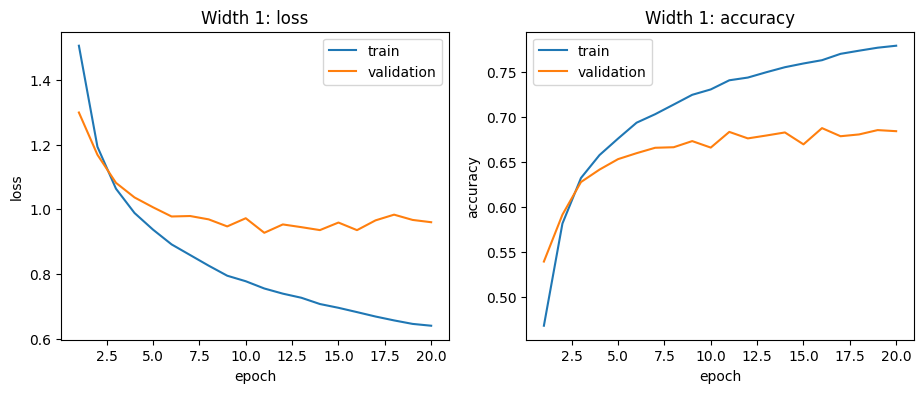

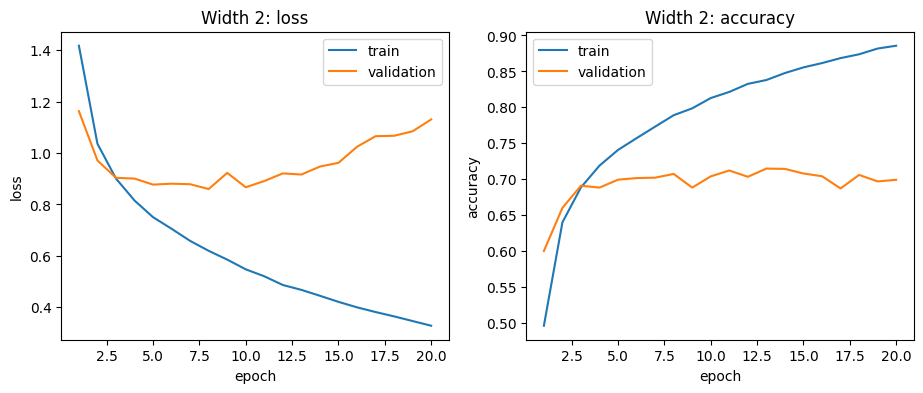

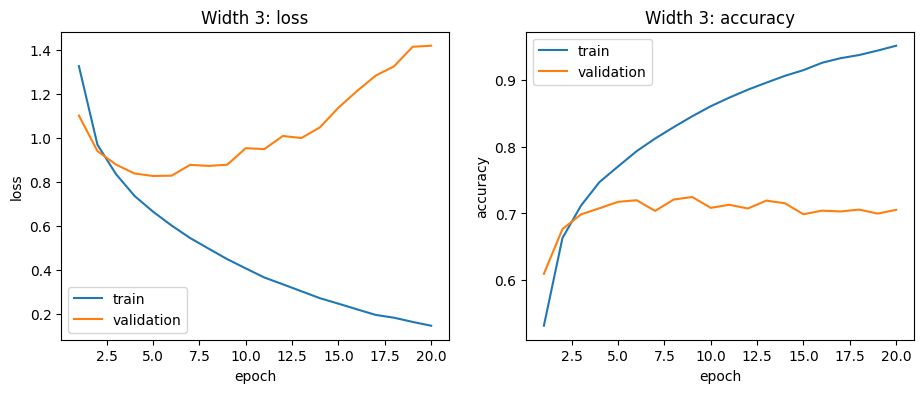

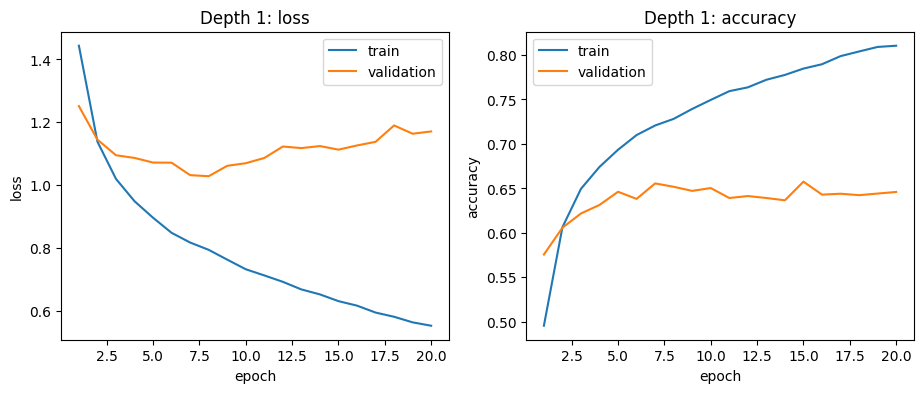

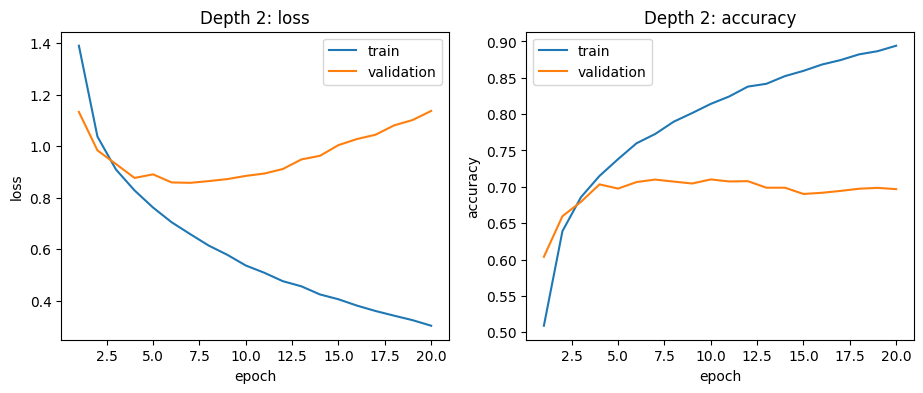

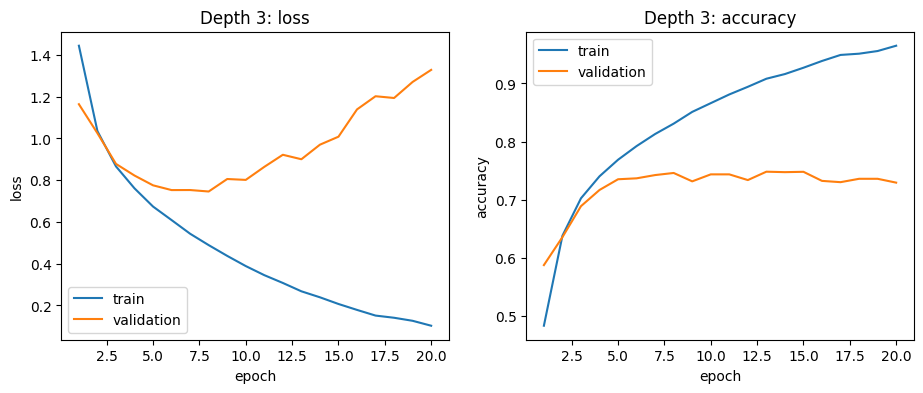

In [8]:
# Plot Width Experiment Graphs
for name, result in width_results.items():
    plot_history(result["history"], name)

# Plot Depth Experiment Graphs
for name, result in depth_results.items():
    plot_history(result["history"], name)

## 9. Conclusion

This experiment investigated the effects of CNN width and depth on CIFAR-10 image classification performance.

The width experiment showed that the configuration with filters [64, 128] achieved the highest validation accuracy of 70.54% among the tested width configurations.

The depth experiment achieved a higher validation accuracy of 72.96% using the configuration [32, 64, 128]. This indicates that increasing the number of convolutional layers was more effective than increasing the number of filters in the tested configurations.

Overall, the depth configuration achieved better validation performance with fewer trainable parameters than the best width configuration. However, the results also suggested possible overfitting. Therefore, selecting a suitable CNN architecture requires considering both classification performance and its ability to generalise to unseen data.